# **Importing Necessery Libraries**

We install `xgboost` and `catboost` since they are not pre-installed by default (unlike scikit-learn/seaborn/plotly), because we plan to compare them against Linear Regression, Decision Tree, Random Forest, and SVM later in the Modeling section.

In [ ]:
!pip install xgboost catboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# **Data Representation & Cleaning**

## **Data Representation**

In [ ]:
df = pd.read_csv("/content/listings.csv")

In [ ]:
df.shape

(30259, 90)

## **Drop Unneeded Columns**

**Why these columns are dropped:**
- **IDs & scrape metadata** (`id`, `scrape_id`, `last_scraped`, host/listing URLs, etc.) — pure identifiers with no predictive relationship to price.
- **Free-text fields** (`name`, `description`, `neighborhood_overview`, host bio text) — would need NLP to extract any signal; out of scope for this project.
- **Redundant/duplicate location columns** — we already keep `neighbourhood_cleansed` as the single, cleaned location feature.
- **Pre-computed price-quote / availability-detail columns** — either duplicate information we already have or risk leaking target-related information.


In [ ]:
#Drop all of ids
df=df.drop(columns=["id","scrape_id","host_id","host_profile_id","host_identity_verified"])

In [ ]:
# Drop all of urls
df=df.drop(columns=["listing_url","host_url","host_profile_url","host_picture_url",'picture_url','host_thumbnail_url'])

In [ ]:
# Drop all of hosts
df=df.drop(columns=["host_name","host_since","hosts_time_as_user_years","hosts_time_as_user_months",
		"hosts_time_as_host_years","hosts_time_as_host_months","host_location",
		"host_about","host_response_time","host_response_rate","host_acceptance_rate",
		"host_is_superhost","host_neighbourhood","host_listings_count","host_total_listings_count",
		"host_verifications","host_has_profile_pic"])

In [ ]:
columns_to_drop = [
    # Metadata
    "last_scraped",
    "source",

    # Text (NLP)
    "name",
    "description",

    # Null / Redundant
    "neighborhood_overview",
    "neighbourhood",
    "neighbourhood_group_cleansed",

    # Price quote columns
    "price_quote_checkin_date",
    "price_quote_checkout_date",
    "price_quote_total_price",
    "price_quote_price_per_night",
    "price_quote_raw",

    # Nights
    "maximum_nights",
    "minimum_minimum_nights",
    "maximum_minimum_nights",
    "minimum_maximum_nights",
    "maximum_maximum_nights",
    "minimum_nights_avg_ntm",
    "maximum_nights_avg_ntm",

    # Availability
    "calendar_updated",
    "has_availability",
    "availability_30",
    "availability_60",
    "availability_90",
    "calendar_last_scraped",
    "availability_eoy",

    # Reviews
    "number_of_reviews_ly",
    "first_review",
    "last_review",

    # Leakage
    "estimated_occupancy_l365d",
    "estimated_revenue_l365d",

    # Other
    "review_scores_value",
    "license",
    "instant_bookable",

    # Host listing counts
    "calculated_host_listings_count",
    "calculated_host_listings_count_entire_homes",
    "calculated_host_listings_count_private_rooms",
    "calculated_host_listings_count_shared_rooms",
]

df = df.drop(columns=columns_to_drop)

In [ ]:
df.shape

(30259, 24)

## **Missing Values**

**Overall strategy for missing values:** we handle each feature according to *what kind* of feature it is, not with one blanket rule:
- Count-based features (`bedrooms`, `beds`) → filled with the **median**, since a median count is more realistic than a mean (which can be pulled by outliers) and keeps the value an integer-like typical case.
- `bathrooms` → mostly recoverable from the text column `bathrooms_text`, so we parse it before falling back to the median for the few that remain.
- Review-related features → missing almost always means "no reviews yet", which is itself meaningful information, not something to just impute blindly — see the Reviews section below.


Work on a **copy** of the raw dataframe (`df_clean`) so the original `df` stays untouched and can always be re-inspected if needed.

In [ ]:
df_clean=df.copy()

In [ ]:
df_clean.isnull().sum()

,0
neighbourhood_cleansed,0
latitude,0
longitude,0
property_type,0
room_type,0
accommodates,0
bathrooms,10112
bathrooms_text,159
bedrooms,10973
beds,9420


`price` is our target — a row with a missing target can't be used for training or evaluation, so we drop those rows outright rather than impute them.

In [ ]:
df_clean=df_clean.dropna(subset=['price'])

In [ ]:
df_clean.isnull().sum()

,0
neighbourhood_cleansed,0
latitude,0
longitude,0
property_type,0
room_type,0
accommodates,0
bathrooms,2371
bathrooms_text,151
bedrooms,7535
beds,1740


**`bedrooms`:** filled with the **median** — it's a count-based feature, so the median gives a realistic "typical" number of bedrooms without being skewed by a handful of unusually large listings.

In [ ]:
df_clean['bedrooms'].isnull().mean()*100

np.float64(35.02207762026493)

In [ ]:
df_clean['bedrooms'].dtype

dtype('float64')

In [ ]:
df_clean['bedrooms'].describe()

,bedrooms
count,13980.000000
mean,1.610658
std,0.955847
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,19.000000


In [ ]:
df_clean["bedrooms"].value_counts().sort_index()

,count
bedrooms,
0.0,14
1.0,8357
2.0,3617
3.0,1405
4.0,387
5.0,126
6.0,44
7.0,11
8.0,7


In [ ]:
df_clean['bedrooms']=df_clean['bedrooms'].fillna(df_clean['bedrooms'].median())

**`bathrooms` / `bathrooms_text`:** the numeric `bathrooms` column has more missing values than `bathrooms_text`, which is a free-text field like `"1.5 baths"` or `"Half-bath"`. We recover the numeric value by:
1. Extracting the leading number from the text with a regex.
2. Handling the special case of `"half-bath"` phrasing by mapping it to `0.5`.
3. Falling back to the **median** only for the small remainder (31 rows) that still had no usable information in either column.


In [ ]:
df_clean['bathrooms'].isnull().sum()

np.int64(2371)

In [ ]:
df_clean["bathrooms"].describe()

,bathrooms
count,19144.000000
mean,1.212834
std,0.541929
min,0.500000
25%,1.000000
50%,1.000000
75%,1.000000
max,15.500000


In [ ]:
df_clean["bathrooms"].value_counts().sort_index()

,count
bathrooms,
0.5,75
1.0,15332
1.5,855
2.0,2232
2.5,227
3.0,224
3.5,66
4.0,78
4.5,18


In [ ]:
df_clean[df_clean["bathrooms"].isna()][["bathrooms", "bathrooms_text"]].head(20)

,bathrooms,bathrooms_text
14,NaN,1 shared bath
17,NaN,1 shared bath
24,NaN,1 shared bath
26,NaN,1 bath
38,NaN,2 baths
45,NaN,1 bath
54,NaN,2 baths
55,NaN,2 baths
60,NaN,0 shared baths
67,NaN,1 bath


Used to pull specific parts out of text data using Regular Expressions
To convert text to number ( It searches every text for a number )
Should be a number to convert


In [ ]:
# Extract the numeric value from bathrooms_text
bathrooms_from_text = (df_clean["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float))

Now If text contain Half bath, we will assign it .5 ( Another Regular Expressions)

In [ ]:
# Assign 0.5 to half-bath entries
mask = df_clean["bathrooms_text"].str.contains("Half-bath", na=False)
bathrooms_from_text.loc[mask] = 0.5

Now we fil missing values on bathrooms

In [ ]:
df_clean["bathrooms"] = df_clean["bathrooms"].fillna(bathrooms_from_text)

In [ ]:
df_clean["bathrooms"].isnull().sum()

np.int64(31)

still there is 31 rows with NaN, so we filled it with median

In [ ]:
df_clean['bathrooms']=df_clean['bathrooms'].fillna(df_clean['bathrooms'].median())

In [ ]:
df_clean['bathrooms'].isnull().sum()

np.int64(0)

In [ ]:
df_clean = df_clean.drop(columns=["bathrooms_text"]) # Not need it anymore (:

**`beds`:** rather than a single global median, we try to recover more accurate values by taking the **median number of beds within each `bedrooms` group** (a 3-bedroom listing typically has more beds than a studio, so grouping gives a better estimate than one overall median). A small number of rows (16) had inconsistent combinations (e.g. 12 bedrooms, or 0 bedrooms) that couldn't be reasonably estimated this way, so those rows were dropped instead of guessed at.


In [ ]:

df_clean['beds'].isnull().sum()

np.int64(1740)

In [ ]:
df_clean["beds"].value_counts().sort_index()

,count
beds,
1.0,11745
2.0,4655
3.0,1802
4.0,914
5.0,310
6.0,165
7.0,68
8.0,70
9.0,14


In [ ]:
df_clean.groupby("bedrooms")["beds"].median()

,beds
bedrooms,
0.0,NaN
1.0,1.0
2.0,2.0
3.0,3.0
4.0,4.0
5.0,5.0
6.0,7.0
7.0,6.0
8.0,11.0


In [ ]:
df_clean["beds"] = df_clean["beds"].fillna(
    df_clean.groupby("bedrooms")["beds"].transform("median")
)

In [ ]:
df_clean['beds'].isnull().sum()

np.int64(16)

In [ ]:
df_clean['beds'].describe()

,beds
count,21499.000000
mean,1.697846
std,1.241151
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,40.000000


In [ ]:
df_clean = df_clean.dropna(subset=["beds"])

In [ ]:
df_clean['beds'].isnull().sum()


np.int64(0)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21499 entries, 0 to 30258
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   neighbourhood_cleansed       21499 non-null  object 
 1   latitude                     21499 non-null  float64
 2   longitude                    21499 non-null  float64
 3   property_type                21499 non-null  object 
 4   room_type                    21499 non-null  object 
 5   accommodates                 21499 non-null  int64  
 6   bathrooms                    21499 non-null  float64
 7   bedrooms                     21499 non-null  float64
 8   beds                         21499 non-null  float64
 9   amenities                    21499 non-null  object 
 10  price                        21499 non-null  object 
 11  minimum_nights               21498 non-null  float64
 12  availability_365             21499 non-null  int64  
 13  number_of_reviews    

**Review-related features:** missing values here are concentrated in two groups — review *activity* counts (`number_of_reviews`, `number_of_reviews_ltm`, `number_of_reviews_l30d`) and review *score* columns (`review_scores_rating`, `review_scores_accuracy`, `review_scores_cleanliness`, `review_scores_checkin`, `review_scores_communication`, `review_scores_location`). In almost every case, a missing review value simply means **the listing has no reviews yet** — that's meaningful information, not something to impute away silently.

So the approach is:
1. **Feature-engineer a `has_reviews` flag first**, so the model can explicitly learn "no reviews yet" as its own signal, instead of confusing it with a genuinely low score.
2. **Then** fill the remaining NaNs in `review_scores_rating` with `0`, since after step 1 the model already knows *why* it's 0.
3. When we looked at the **correlation heatmap** later (see EDA section), the individual score sub-columns (`accuracy`, `cleanliness`, `checkin`, `communication`, `location`) were all highly correlated with each other and with the overall `review_scores_rating` — keeping all of them would add redundant, near-duplicate information, so we drop the sub-columns and keep `review_scores_rating` as the single representative score.


In [ ]:
df_clean[[
"review_scores_rating",
"review_scores_accuracy",
"review_scores_cleanliness",
"review_scores_checkin",
"review_scores_communication",
"review_scores_location"
]].isnull().mean()*100

,0
review_scores_rating,28.233871
review_scores_accuracy,28.233871
review_scores_cleanliness,28.233871
review_scores_checkin,28.233871
review_scores_communication,28.233871
review_scores_location,28.238523


In [ ]:
df_clean["has_reviews"] = (df_clean["number_of_reviews"] > 0).astype(int)

In [ ]:
df_clean["review_scores_rating"] = df_clean["review_scores_rating"].fillna(0)

In [ ]:
df_clean['review_scores_rating'].info()

<class 'pandas.core.series.Series'>
Index: 21499 entries, 0 to 30258
Series name: review_scores_rating
Non-Null Count  Dtype  
--------------  -----  
21499 non-null  float64
dtypes: float64(1)
memory usage: 335.9 KB


**`minimum_nights`:** handled next since it's a booking-policy field set directly by the host, not something guests review — checked separately from the reviews block above.

In [ ]:
df_clean['minimum_nights'].isnull().sum()

np.int64(1)

In [ ]:
df_clean = df_clean.dropna(subset=["minimum_nights"])

Drop the redundant review sub-score columns identified above, keeping only `review_scores_rating`.

*Note:* `review_scores_rating` was already fully filled with `0` in the step above (no `NaN`s remain), so the `.fillna(median)` line below has no actual effect on the data — it's dead code, left in place but harmless.


In [ ]:
review_cols = [
    "review_scores_accuracy",
    "review_scores_cleanliness",
    "review_scores_checkin",
    "review_scores_communication",
    "review_scores_location"
]

df_clean = df_clean.drop(columns=review_cols)

df_clean['review_scores_rating'] = df_clean['review_scores_rating'].fillna(df_clean['review_scores_rating'].median())

**`reviews_per_month`:** same logic as `has_reviews` — a listing with no reviews naturally has 0 reviews per month, so filling with `0` is consistent rather than an arbitrary choice.

In [ ]:
df_clean['reviews_per_month']=df_clean['reviews_per_month'].fillna(0)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21498 entries, 0 to 30258
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   neighbourhood_cleansed  21498 non-null  object 
 1   latitude                21498 non-null  float64
 2   longitude               21498 non-null  float64
 3   property_type           21498 non-null  object 
 4   room_type               21498 non-null  object 
 5   accommodates            21498 non-null  int64  
 6   bathrooms               21498 non-null  float64
 7   bedrooms                21498 non-null  float64
 8   beds                    21498 non-null  float64
 9   amenities               21498 non-null  object 
 10  price                   21498 non-null  object 
 11  minimum_nights          21498 non-null  float64
 12  availability_365        21498 non-null  int64  
 13  number_of_reviews       21498 non-null  int64  
 14  number_of_reviews_ltm   21498 non-null  int

In [ ]:
df_clean.isnull().sum()

,0
neighbourhood_cleansed,0
latitude,0
longitude,0
property_type,0
room_type,0
accommodates,0
bathrooms,0
bedrooms,0
beds,0
amenities,0


In [ ]:
df_clean.dtypes

,0
neighbourhood_cleansed,object
latitude,float64
longitude,float64
property_type,object
room_type,object
accommodates,int64
bathrooms,float64
bedrooms,float64
beds,float64
amenities,object


## **Duplicates**

Check and remove duplicate rows from **`df_clean`** — the cleaned working copy — rather than the raw `df`. Checking `df` would miss duplicates that only become identical after dropping columns/cleaning, and wouldn't actually affect the data we use downstream.

In [ ]:
df_clean.duplicated().sum()

np.int64(224)

In [ ]:
df_clean.drop_duplicates(inplace=True)

## **Fixing Data Types**

`price` is stored as text (e.g. `"$1,200.00"`) because of the `$` sign and thousands-separator commas, so pandas reads it as an `object` column instead of a number. We strip both characters out and cast it to `float` before it can be used in any numeric calculation or model.

In [ ]:
print(df_clean[['price']].dtypes)
print("--------------------------")
print(df_clean[['price']].head())
print("--------------------------")
df_clean[['price']].info()

price    object
dtype: object
--------------------------
     price
0  $113.97
1  $117.27
2   $80.06
3   $77.17
4  $202.47
--------------------------
<class 'pandas.core.frame.DataFrame'>
Index: 21274 entries, 0 to 30258
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   price   21274 non-null  object
dtypes: object(1)
memory usage: 332.4+ KB


In [ ]:
df_clean['price'] = (
    df_clean['price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [ ]:
print(df_clean[['price']].dtypes)
print("--------------------------")
print(df_clean[['price']].head())

price    float64
dtype: object
--------------------------
    price
0  113.97
1  117.27
2   80.06
3   77.17
4  202.47


# **Exploratory Data Analysis (EDA)**


**Plan for this section:**
1. Look at the target (`price`) distribution first — it's right-skewed, which is why we later apply a log transform before modeling.
2. Look at numerical and categorical feature distributions on their own.
3. Compare `price` across categories, and check the full correlation matrix.
4. Finish with a few **multivariate** (3-feature) plots — `x`, `y`, and `hue`/`size` together — to catch relationships a simple 2D plot can't show.


In [ ]:
print(df_clean['price'].describe())

hist_fig = px.histogram(df_clean, x='price', nbins=200, color_discrete_sequence=['#6c5ce7'])
box_fig = px.box(df_clean, y='price', color_discrete_sequence=['#6c5ce7'])

fig = make_subplots(rows=1, cols=2, column_widths=[0.7, 0.3],
                     subplot_titles=['Price Distribution', 'Price Outliers'])
fig.add_trace(hist_fig.data[0], row=1, col=1)
fig.add_trace(box_fig.data[0], row=1, col=2)
fig.update_layout(title_text='Price Distribution & Outliers', showlegend=False)
fig.show()

count    21274.000000
mean       275.595929
std        528.521065
min          4.580000
25%         96.900000
50%        173.500000
75%        299.000000
max      30972.960000
Name: price, dtype: float64


**What to look for:** the histogram shows a long right tail (a small number of very expensive listings), and the boxplot's outlier points confirm it. This is exactly the shape that justifies applying `np.log1p` to `price` later in Preprocessing — a heavily skewed target makes regression models (especially Linear Regression) fit poorly.

We split the remaining columns into `num_cols` and `cat_cols` here so the next few plots can loop over each group programmatically, instead of typing out every column name by hand for every plot.

In [ ]:
num_cols = ["accommodates", "bathrooms", "bedrooms", "beds", "minimum_nights",
            "availability_365", "number_of_reviews", "review_scores_rating"]
cat_cols = ["room_type", "has_reviews"]

**Numerical feature distributions (Plotly):** using an interactive faceted histogram so each subplot can be hovered/zoomed individually — useful for spotting exactly where an odd spike or outlier sits.

**Same distributions in Seaborn:** a static, print-friendly version for a quick side-by-side comparison, complementing the interactive Plotly version above rather than repeating it.

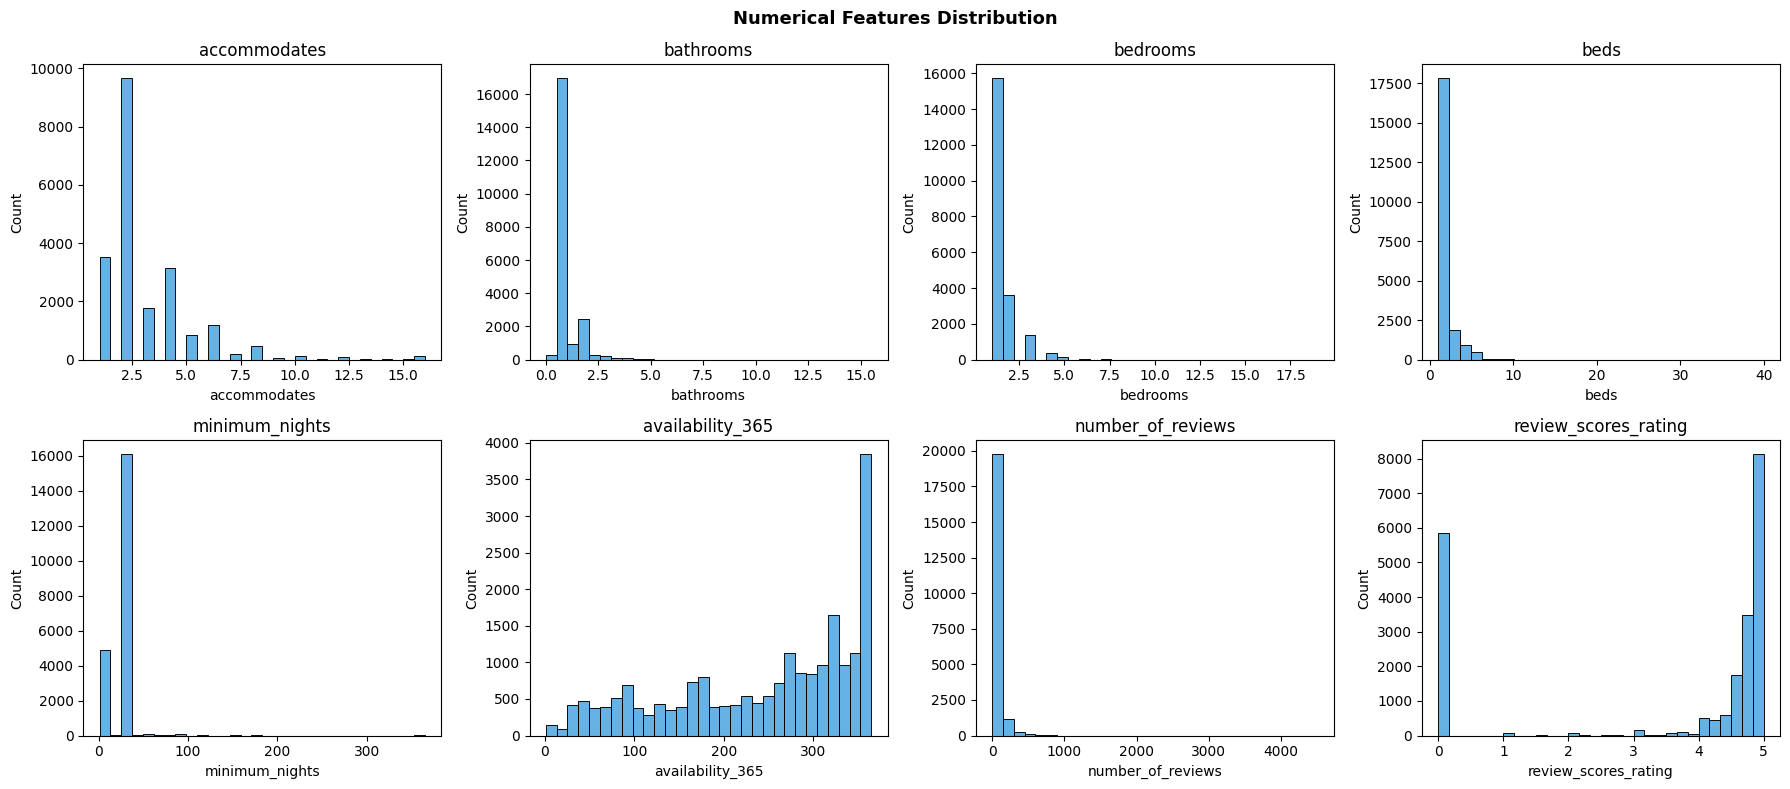

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df_clean, x=col, bins=30, color='#3498db', ax=ax)
    ax.set_title(col)

plt.suptitle("Numerical Features Distribution", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


**What to look for:** most count-based features (`bedrooms`, `bathrooms`, `beds`, `accommodates`) cluster around small values with a long thinning tail — consistent with typical short-term rentals being modest-sized. `minimum_nights` and `number_of_reviews` are usually the most heavily skewed.

**Price vs each numerical feature:** a quick scan across all numerical columns at once, to shortlist which ones are worth a closer, individual look.

In [ ]:
df_num_price_long = df_clean[num_cols + ['price']].melt(id_vars='price', var_name='feature', value_name='value')

fig = px.scatter(df_num_price_long, x='value', y='price', facet_col='feature', facet_col_wrap=4,
                  opacity=0.3, color_discrete_sequence=['#e17055'], log_y=True)
fig.update_yaxes(matches=None)
fig.update_xaxes(matches=None)
fig.update_layout(title_text='Numerical Features vs Price', showlegend=False, height=600)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()


**What to look for:** an upward trend as a feature increases (e.g. `accommodates`) suggests it's a real price driver; a flat/scattered cloud for a feature suggests it's contributing little on its own.

**Categorical feature counts:** how balanced or imbalanced each category is — this matters directly for the encoding choice we make later (One-Hot vs Frequency Encoding).

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=cat_cols)

colors = ['#0984e3', '#fdcb6e']
for i, col in enumerate(cat_cols):
    counts = df_clean[col].value_counts()
    fig.add_trace(go.Bar(x=counts.index.astype(str), y=counts.values,
                          marker_color=colors[i], showlegend=False), row=1, col=i + 1)

fig.update_layout(title_text='Categorical Features Distribution', height=450)
fig.show()


**What to look for:** `room_type` has only a handful of categories, so One-Hot Encoding stays manageable. Features with many rare categories (like `neighbourhood_cleansed` or `property_type`) are the ones where One-Hot would blow up the feature space — that's why we use Frequency Encoding for those instead (see Preprocessing).

**Price by category:** does the category actually separate listings into different price levels, or do they overlap heavily?

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=[f'Price by {c}' for c in cat_cols])

colors = ['#e84393', '#00cec9']
for i, col in enumerate(cat_cols):
    for j, cat_val in enumerate(sorted(df_clean[col].unique(), key=str)):
        fig.add_trace(
            go.Box(y=df_clean.loc[df_clean[col] == cat_val, 'price'], name=str(cat_val),
                   marker_color=colors[j % len(colors)], showlegend=False),
            row=1, col=i + 1
        )

fig.update_yaxes(type='log')
fig.update_layout(title_text='Categorical Features vs Price', height=500)
fig.show()


**What to look for:** clear separation between boxes (e.g. across `room_type`) is a strong signal that category is a useful predictor.

**Correlation heatmap:** this is the plot referenced earlier in the Missing Values section — checking it is what showed that the individual review sub-scores (`accuracy`, `cleanliness`, `checkin`, `communication`, `location`) were all highly correlated with each other and with `review_scores_rating`, which is why we dropped the sub-scores and kept only the overall rating.

*(Note: by the time this cell runs, those sub-score columns are already gone from `df_clean` — this heatmap reflects the cleaned feature set. The correlation check that originally motivated dropping them was done on the data before that cleanup step.)*


In [ ]:
df_corr = df_clean[num_cols + ["price"]].copy()
corr = df_corr.corr()

fig = px.imshow(corr, text_auto=".2f", color_continuous_scale='Tealrose', zmin=-1, zmax=1)
fig.update_layout(title='Correlation Heatmap', height=600)
fig.show()


**What to look for:** two things — which features are most correlated with `price` (candidates for strong predictors), and which *pairs of features* are highly correlated with each other (multicollinearity risk, especially relevant for Linear Regression).

## **Multivariate Analysis (3 Features)**


A 2D plot can only show two variables at once. These next few plots deliberately combine **three** variables — `x`, `y`, and `hue` (or `size`) — to catch relationships that only show up when you look at more than one feature together.

**Price vs Accommodates, by Room Type:** checks whether the size-price relationship looks the same across every room type, or whether it differs (an interaction effect).

In [ ]:
# Price vs Accommodates, colored by Room Type
fig = px.scatter(df_clean, x='accommodates', y='price', color='room_type',
                  opacity=0.5, color_discrete_sequence=px.colors.qualitative.Bold,
                  log_y=True, title='Price vs Accommodates, by Room Type')
fig.show()


**Price vs Bedrooms, sized/colored by Bathrooms:** combines two "size" dimensions at once, since bedrooms and bathrooms together describe a listing's capacity better than either alone.

In [ ]:
# Price vs Bedrooms, with point size/color representing Bathrooms
fig = px.scatter(df_clean, x='bedrooms', y='price', size='bathrooms', color='bathrooms',
                  opacity=0.5, color_continuous_scale='Plasma', log_y=True,
                  title='Price vs Bedrooms, sized/colored by Bathrooms')
fig.show()


**Price vs Availability, colored by `has_reviews`:** checks whether listings that already have reviews behave differently (in price vs. availability) from brand-new, unreviewed listings.

In [ ]:
# Price vs Availability, colored by whether the listing has reviews
fig = px.scatter(df_clean, x='availability_365', y='price', color='has_reviews',
                  opacity=0.4, color_discrete_sequence=['#d63031', '#00b894'], log_y=True,
                  title='Price vs Availability, by Has Reviews')
fig.show()


**Price by Room Type, split by `has_reviews`:** checks whether the room-type price pattern we saw earlier holds up the same way for reviewed vs. unreviewed listings, or whether it shifts.

In [ ]:
# Price by Room Type, split by whether the listing has reviews
fig = px.box(df_clean, x='room_type', y='price', color='has_reviews',
             color_discrete_sequence=['#d63031', '#00b894'], log_y=True,
             title='Price by Room Type, split by Has Reviews')
fig.show()


**EDA takeaways heading into Preprocessing:**
- `price` is right-skewed → log-transform the target.
- Room type and size features show real separation/trend vs. price → keep them, encode room type with One-Hot.
- `neighbourhood_cleansed` / `property_type` have many categories → use Frequency Encoding instead of One-Hot to avoid an explosion of columns.
- Review sub-scores were redundant with each other → already dropped, keeping just `review_scores_rating` plus the engineered `has_reviews` flag.


# **Data Preprocessing**

Turn the EDA takeaways above into concrete transformations: encode categorical features, transform the skewed target, and prepare the train/test split with scaling.

## **Data Encoding**

Two different encoding strategies are used below, chosen based on how many categories each column has (see the Categorical Distribution plot in EDA).

**`amenities`:** this column is free text listing services (e.g. `"Wifi, Kitchen, Pool, ..."`), which isn't usable as-is. Rather than trying to encode every individual amenity (which would create dozens of sparse columns), we reduce it to a single, meaningful number — **the count of amenities listed** — and drop the original text column.

In [ ]:
df_clean['amenities_count'] = df_clean['amenities'].astype(str).apply(lambda x: len(x.split(',')))
df_clean = df_clean.drop(columns=['amenities'])

print(df_clean[['amenities_count']].head())

   amenities_count
0               49
1               26
2               18
3               22
4               51


One-Hot Encoding for room type

**Why One-Hot here:** `room_type` has only a few categories with no natural order between them (e.g. "Entire home" isn't "more" than "Private room"), so One-Hot Encoding is the standard, safe choice.

In [ ]:
df_clean = pd.get_dummies(df_clean, columns=['room_type'], drop_first=True, dtype=int)

print(df_clean.filter(like='room_type').columns.tolist())

print(df_clean[['room_type_Private room', 'room_type_Shared room','room_type_Hotel room']].head())

['room_type_Hotel room', 'room_type_Private room', 'room_type_Shared room']
   room_type_Private room  room_type_Shared room  room_type_Hotel room
0                       1                      0                     0
1                       0                      0                     0
2                       1                      0                     0
3                       1                      0                     0
4                       1                      0                     0


Frequency Encoding for neighbourhood_cleansed and property_type

**Why Frequency Encoding here instead of One-Hot:** `neighbourhood_cleansed` and `property_type` have far more distinct categories. One-Hot Encoding them would create dozens/hundreds of mostly-empty columns (high dimensionality, mostly zeros). Frequency Encoding instead replaces each category with *how common it is* — a single numeric column that still carries useful signal (rare vs. common location/type) without exploding the feature space.

In [ ]:
freq_neighbourhood = df_clean['neighbourhood_cleansed'].value_counts()
df_clean['neighbourhood_encoded'] = df_clean['neighbourhood_cleansed'].map(freq_neighbourhood)

freq_property = df_clean['property_type'].value_counts()
df_clean['property_encoded'] = df_clean['property_type'].map(freq_property)

df_clean = df_clean.drop(columns=['neighbourhood_cleansed', 'property_type'])

In [ ]:
print(freq_neighbourhood.head())

neighbourhood_cleansed
Bedford-Stuyvesant    1485
Midtown               1301
Harlem                1061
Hell's Kitchen        1055
Upper East Side        877
Name: count, dtype: int64


In [ ]:
print(freq_property.head())

property_type
Entire rental unit             8631
Private room in rental unit    4648
Private room in home           2131
Room in hotel                  1263
Entire home                    1036
Name: count, dtype: int64


## **Target Transformation (Log Price)**

Target Transformation to avoid Right-Skewed

In [ ]:
df_clean['price_log'] = np.log1p(df_clean['price'])

              price     price_log
count  21274.000000  21274.000000
mean     275.595929      5.196391
std      528.521065      0.833126
min        4.580000      1.719189
25%       96.900000      4.583947
50%      173.500000      5.161925
75%      299.000000      5.703782
max    30972.960000     10.340902


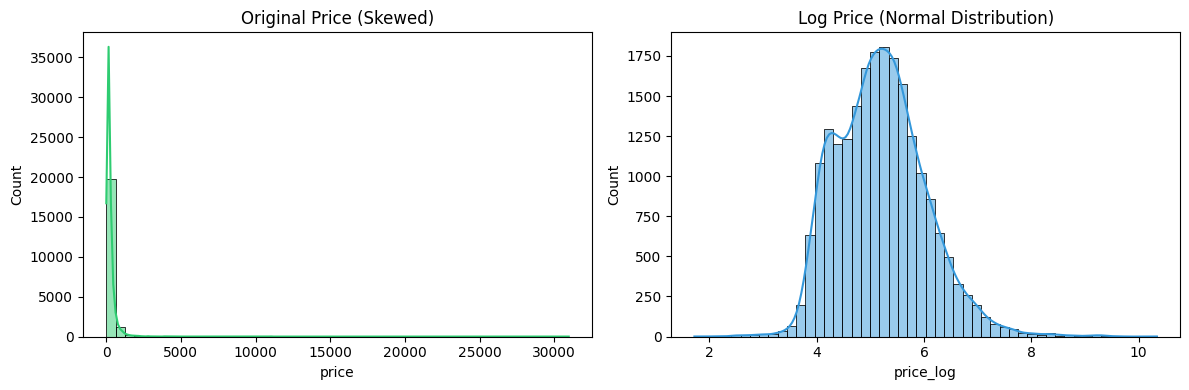

In [ ]:
print(df_clean[['price', 'price_log']].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean['price'], bins=50, kde=True, color='#2ecc71', ax=axes[0])
axes[0].set_title("Original Price (Skewed)")

sns.histplot(df_clean['price_log'], bins=50, kde=True, color='#3498db', ax=axes[1])
axes[1].set_title("Log Price (Normal Distribution)")

plt.tight_layout()
plt.show()

To ensure there are no NaN values

In [ ]:
print("NAN values :", df_clean.isna().sum().sum())

NAN values : 0


## **Define Features X and Target y, and Data Splitting**

An 80/20 train/test split with a fixed `random_state` so the split is reproducible every time this notebook is re-run.

Splitting

In [ ]:
x = df_clean.drop(columns=['price', 'price_log'])
y = df_clean['price_log']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## **Data Scaling**

**Why scaling matters here:** tree-based models (Decision Tree, Random Forest, XGBoost, CatBoost) don't need it, but **Linear Regression** and especially **SVM** are sensitive to feature scale — without scaling, features with naturally larger numeric ranges would dominate the model regardless of their real importance.

Feature Scaling

In [ ]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## **Feature Summary**

number of features and the columns

In [ ]:
print("number of features : ", x.shape[1])
print("columns : \n", x.columns.tolist())

number of features :  20
columns : 
 ['latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'review_scores_rating', 'reviews_per_month', 'has_reviews', 'amenities_count', 'room_type_Hotel room', 'room_type_Private room', 'room_type_Shared room', 'neighbourhood_encoded', 'property_encoded']


## **Multivariate Analysis: Feature-Target Correlation**

A final correlation check against the target, now on the fully-encoded and scaled feature set — a sanity check before modeling that nothing looks obviously broken (e.g. an encoded column ending up with near-zero variance).

Relationship between features and price

In [ ]:
correlations = x.corrwith(y).abs().sort_values(ascending=False)
print("Relationship between features and price :")
print(correlations.head(18))

Relationship between features and price :
accommodates              0.521446
room_type_Private room    0.395358
beds                      0.389219
minimum_nights            0.380697
bedrooms                  0.365158
longitude                 0.276198
bathrooms                 0.245920
amenities_count           0.203109
room_type_Hotel room      0.160627
neighbourhood_encoded     0.115024
number_of_reviews_ltm     0.111959
number_of_reviews_l30d    0.101532
reviews_per_month         0.097516
room_type_Shared room     0.083131
has_reviews               0.081740
availability_365          0.072896
property_encoded          0.072458
review_scores_rating      0.070604
dtype: float64


# **Data Modeling**

**Modeling plan:**
1. Train a simple **baseline** model first (Linear Regression) to have a reference point.
2. Train five more models — Decision Tree, Random Forest, XGBoost, SVM, and CatBoost — and compare all six using MAE, MSE, RMSE, R², and Adjusted R².
3. Pick the **best 4** models (by RMSE) and re-train each on 1%, 10%, and 100% of the training data, to see how much each model actually benefits from more data.
4. Tune the strongest model (**Random Forest**) with hyperparameter search, and compare its performance before vs. after tuning.


## **Helper Function: Adjusted R²**

R² alone can look artificially high just because we add more features, even if they don't really help. Adjusted R² corrects for the number of features used, so it only goes up if a feature actually improves the model. We'll report it next to R² and MSE for every model.

In [ ]:
def adjusted_r2_score(r2, n_samples, n_features):
    return 1 - (1 - r2) * (n_samples - 1) / (n_samples - n_features - 1)

n_features = x_test_scaled.shape[1]
n_test_samples = x_test_scaled.shape[0]


## **Baseline Model (Train & Test)**

A baseline gives us a minimum bar every other model has to beat — if a more complex model can't outperform plain Linear Regression, it's not worth the added complexity.

Baseline Model (Linear Regression)

In [ ]:
linear_model = LinearRegression(fit_intercept=True)

linear_model.fit(x_train_scaled, y_train)

linear_pred = linear_model.predict(x_test_scaled)


Evaluate Linear Regression

In [ ]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_pred)
linear_adj_r2 = adjusted_r2_score(linear_r2, n_test_samples, n_features)

print("Linear Regression")
print("MAE :", linear_mae)
print("MSE :", linear_mse)
print("RMSE :", linear_rmse)
print("R2 :", linear_r2)
print("Adjusted R2 :", linear_adj_r2)


Linear Regression
MAE : 0.4087221349105182
MSE : 0.2977809932338676
RMSE : 0.5456931310121721
R2 : 0.5654005296375471
Adjusted R2 : 0.5633476270850555


Decision Tree Model

**Why try Decision Tree:** unlike Linear Regression, it can capture non-linear relationships and interactions between features automatically, without us having to engineer them by hand.

In [ ]:
tree_model = DecisionTreeRegressor(max_depth=10, random_state=42)

tree_model.fit(x_train_scaled, y_train)

tree_pred = tree_model.predict(x_test_scaled)


Evaluate Decision Tree

In [ ]:
tree_mae = mean_absolute_error(y_test, tree_pred)
tree_mse = mean_squared_error(y_test, tree_pred)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_pred)
tree_adj_r2 = adjusted_r2_score(tree_r2, n_test_samples, n_features)

print("Decision Tree")
print("MAE :", tree_mae)
print("MSE :", tree_mse)
print("RMSE :", tree_rmse)
print("R2 :", tree_r2)
print("Adjusted R2 :", tree_adj_r2)


Decision Tree
MAE : 0.3236153547359987
MSE : 0.2131782276082266
RMSE : 0.46171227794831987
R2 : 0.6888748882015461
Adjusted R2 : 0.6874052372246994


Random Forest Model

**Why try Random Forest:** an ensemble of many decision trees averaged together — usually more stable and less prone to overfitting than a single tree.

In [ ]:
forest_model = RandomForestRegressor(n_estimators=200, random_state=42)

forest_model.fit(x_train_scaled, y_train)

forest_pred = forest_model.predict(x_test_scaled)


Evaluate Random Forest

In [ ]:
forest_mae = mean_absolute_error(y_test, forest_pred)
forest_mse = mean_squared_error(y_test, forest_pred)
forest_rmse = np.sqrt(forest_mse)
forest_r2 = r2_score(y_test, forest_pred)
forest_adj_r2 = adjusted_r2_score(forest_r2, n_test_samples, n_features)

print("Random Forest")
print("MAE :", forest_mae)
print("MSE :", forest_mse)
print("RMSE :", forest_rmse)
print("R2 :", forest_r2)
print("Adjusted R2 :", forest_adj_r2)


Random Forest
MAE : 0.264244348990962
MSE : 0.14395263154904211
RMSE : 0.37941090067240046
R2 : 0.7899068817351917
Adjusted R2 : 0.7889144721071104


XGBoost Model

**Why try XGBoost:** a gradient-boosted tree ensemble that often performs very well on tabular data like this, by building trees sequentially where each one corrects the previous one's errors.

In [ ]:
xgb_model = XGBRegressor(n_estimators=200, random_state=42)

xgb_model.fit(x_train_scaled, y_train)

xgb_pred = xgb_model.predict(x_test_scaled)



Evaluate XGBoost

In [ ]:
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_mse = mean_squared_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(y_test, xgb_pred)
xgb_adj_r2 = adjusted_r2_score(xgb_r2, n_test_samples, n_features)

print("XGBoost")
print("MAE :", xgb_mae)
print("MSE :", xgb_mse)
print("RMSE :", xgb_rmse)
print("R2 :", xgb_r2)
print("Adjusted R2 :", xgb_adj_r2)


XGBoost
MAE : 0.2670633815713797
MSE : 0.143333828797132
RMSE : 0.3785945440667786
R2 : 0.7908099996451643
Adjusted R2 : 0.789821856044055


SVM Model (SVR)

**Why try SVM (SVR):** a fundamentally different approach (margin-based, not tree-based) — worth including for comparison, though it's the most sensitive of all six models to feature scaling.

In [ ]:
svm_model = SVR(C=1.0)

svm_model.fit(x_train_scaled, y_train)

svm_pred = svm_model.predict(x_test_scaled)



Evaluate SVM

In [ ]:
svm_mae = mean_absolute_error(y_test, svm_pred)
svm_mse = mean_squared_error(y_test, svm_pred)
svm_rmse = np.sqrt(svm_mse)
svm_r2 = r2_score(y_test, svm_pred)
svm_adj_r2 = adjusted_r2_score(svm_r2, n_test_samples, n_features)

print("SVM")
print("MAE :", svm_mae)
print("MSE :", svm_mse)
print("RMSE :", svm_rmse)
print("R2 :", svm_r2)
print("Adjusted R2 :", svm_adj_r2)


SVM
MAE : 0.2897194007665365
MSE : 0.1720692334642946
RMSE : 0.4148122870218463
R2 : 0.7488718238288468
Adjusted R2 : 0.747685578310797


CatBoost Model

**Why try CatBoost:** another gradient-boosting variant, known for handling messy/real-world tabular data robustly with less manual tuning than XGBoost typically needs.

In [ ]:
catboost_model = CatBoostRegressor(iterations=500, random_state=42, verbose=0)

catboost_model.fit(x_train_scaled, y_train)

catboost_pred = catboost_model.predict(x_test_scaled)



Evaluate CatBoost

In [ ]:
catboost_mae = mean_absolute_error(y_test, catboost_pred)
catboost_mse = mean_squared_error(y_test, catboost_pred)
catboost_rmse = np.sqrt(catboost_mse)
catboost_r2 = r2_score(y_test, catboost_pred)
catboost_adj_r2 = adjusted_r2_score(catboost_r2, n_test_samples, n_features)

print("CatBoost")
print("MAE :", catboost_mae)
print("MSE :", catboost_mse)
print("RMSE :", catboost_rmse)
print("R2 :", catboost_r2)
print("Adjusted R2 :", catboost_adj_r2)


CatBoost
MAE : 0.2579177546793468
MSE : 0.13236744742532058
RMSE : 0.36382337394032366
R2 : 0.8068149954114283
Adjusted R2 : 0.8059024540576798


Compare Models

This table puts all six models side-by-side on the same metrics, so the comparison isn't just "which model feels best" but based on actual numbers.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "SVM",
        "CatBoost"
    ],
    "MAE": [
        linear_mae, tree_mae, forest_mae, xgb_mae, svm_mae, catboost_mae
    ],
    "MSE": [
        linear_mse, tree_mse, forest_mse, xgb_mse, svm_mse, catboost_mse
    ],
    "RMSE": [
        linear_rmse, tree_rmse, forest_rmse, xgb_rmse, svm_rmse, catboost_rmse
    ],
    "R2": [
        linear_r2, tree_r2, forest_r2, xgb_r2, svm_r2, catboost_r2
    ],
    "Adjusted R2": [
        linear_adj_r2, tree_adj_r2, forest_adj_r2, xgb_adj_r2, svm_adj_r2, catboost_adj_r2
    ]
})

results


,Model,MAE,MSE,RMSE,R2,Adjusted R2
0,Linear Regression,0.408722,0.297781,0.545693,0.565401,0.563348
1,Decision Tree,0.323615,0.213178,0.461712,0.688875,0.687405
2,Random Forest,0.264244,0.143953,0.379411,0.789907,0.788914
3,XGBoost,0.267063,0.143334,0.378595,0.790810,0.789822
4,SVM,0.289719,0.172069,0.414812,0.748872,0.747686
5,CatBoost,0.257918,0.132367,0.363823,0.806815,0.805902


## **Select the Best 4 Models (by RMSE)**

Re-training all 6 models across 3 data sizes (1%/10%/100%) would be expensive and mostly redundant — the weakest models won't suddenly become competitive with more data. So we narrow down to the **top 4 by RMSE** before running the data-size experiment.

In [ ]:
all_fitted_models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
    "XGBoost": xgb_model,
    "SVM": svm_model,
    "CatBoost": catboost_model
}

best4_names = results.sort_values("RMSE").head(4)["Model"].tolist()
print("Best 4 models based on Test RMSE:", best4_names)

best4_models = {name: all_fitted_models[name] for name in best4_names}


Best 4 models based on Test RMSE: ['CatBoost', 'XGBoost', 'Random Forest', 'SVM']


# **Model Comparison Across Data Sizes**

**Goal of this section:** see how much each model's performance actually improves as training data grows from 1% → 10% → 100% — a shrinking model doesn't always mean "needs more data"; some models plateau early.

## **Train Each Model on 1%, 10%, and 100% of the Data (Best 4 Models)**


Define Data Sizes



In [ ]:
sizes = {
    "1%": 0.01,
    "10%": 0.10,
    "100%": 1.00
}

models = best4_models

comparison_results = []


Train Models on Different Data Sizes

In [ ]:
for model_name, model in models.items():

    for size_name, size in sizes.items():

        n = int(len(x_train_scaled) * size)

        X_small = x_train_scaled[:n]
        y_small = y_train[:n]

        current_model = clone(model)

        current_model.fit(X_small, y_small)

        pred = current_model.predict(x_test_scaled)

        mse = mean_squared_error(y_test, pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, pred)
        r2 = r2_score(y_test, pred)
        adj_r2 = adjusted_r2_score(r2, n_test_samples, n_features)

        comparison_results.append({
            "Model": model_name,
            "Data Size": size_name,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2,
            "Adjusted R2": adj_r2
        })


## **Compare Metrics Using Bar Graphs**

Create Comparison Table

In [ ]:
comparison_df = pd.DataFrame(comparison_results)

comparison_df

,Model,Data Size,MAE,MSE,RMSE,R2,Adjusted R2
0,CatBoost,1%,0.381193,0.261629,0.511496,0.618163,0.616360
1,CatBoost,10%,0.301542,0.175621,0.419072,0.743688,0.742477
2,CatBoost,100%,0.257918,0.132367,0.363823,0.806815,0.805902
3,XGBoost,1%,0.427996,0.322367,0.567774,0.529518,0.527296
4,XGBoost,10%,0.322550,0.200205,0.447443,0.707808,0.706428
5,XGBoost,100%,0.267063,0.143334,0.378595,0.790810,0.789822
6,Random Forest,1%,0.405337,0.289644,0.538186,0.577276,0.575279
7,Random Forest,10%,0.315422,0.193019,0.439339,0.718296,0.716966
8,Random Forest,100%,0.264244,0.143953,0.379411,0.789907,0.788914
9,SVM,1%,0.405835,0.306142,0.553301,0.553199,0.551088


RMSE Comparison (1%, 10%, 100%)

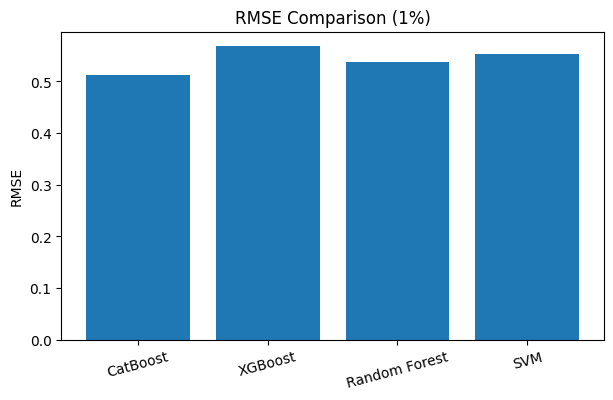

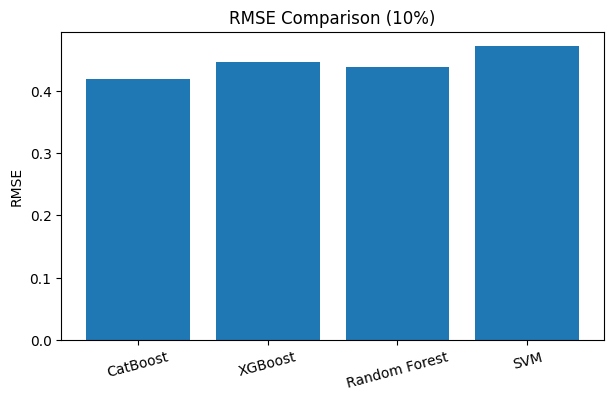

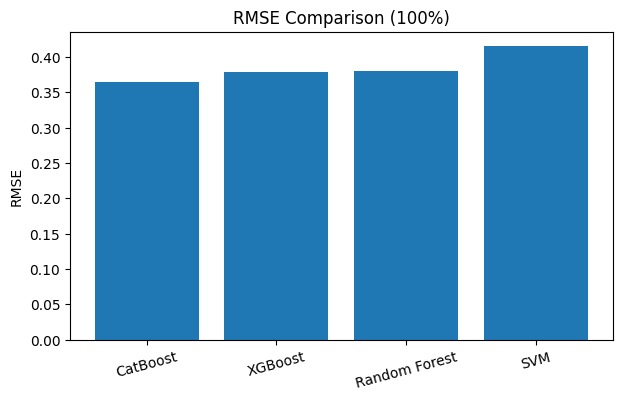

In [ ]:
for size in ["1%", "10%", "100%"]:

    data = comparison_df[comparison_df["Data Size"] == size]

    plt.figure(figsize=(7,4))

    plt.bar(data["Model"], data["RMSE"])

    plt.title(f"RMSE Comparison ({size})")

    plt.ylabel("RMSE")

    plt.xticks(rotation=15)

    plt.show()

Overall RMSE Comparison

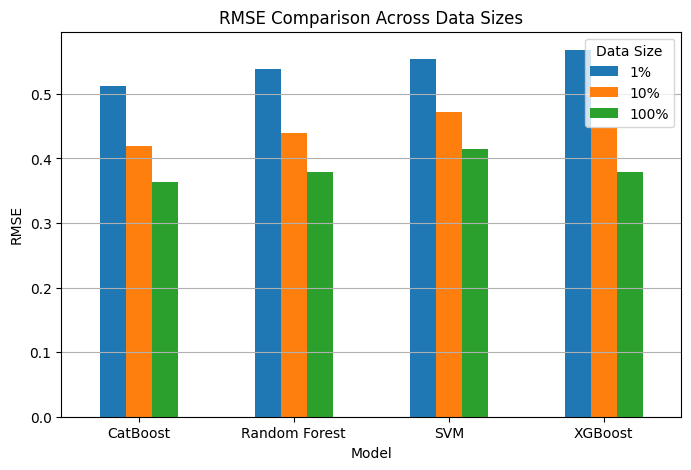

In [ ]:
pivot = comparison_df.pivot(
    index="Model",
    columns="Data Size",
    values="RMSE"
)

pivot.plot(kind="bar", figsize=(8,5))

plt.title("RMSE Comparison Across Data Sizes")

plt.ylabel("RMSE")

plt.xticks(rotation=0)

plt.grid(axis="y")

plt.show()

Overall MSE Comparison

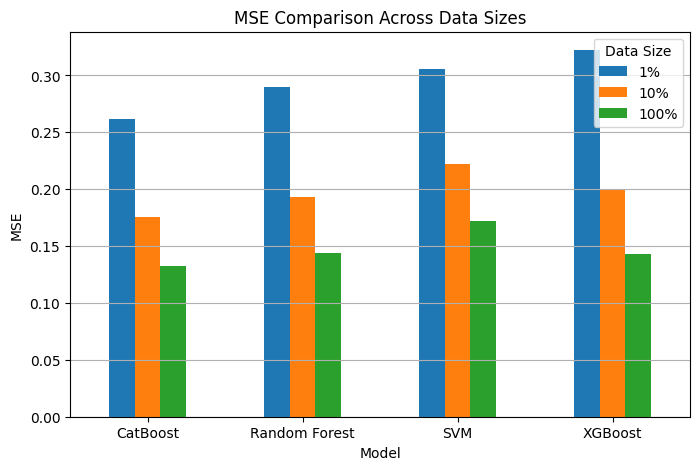

In [ ]:
pivot_mse = comparison_df.pivot(
    index="Model",
    columns="Data Size",
    values="MSE"
)

pivot_mse.plot(kind="bar", figsize=(8,5))

plt.title("MSE Comparison Across Data Sizes")
plt.ylabel("MSE")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()


Overall Adjusted R² Comparison (vs plain R²)

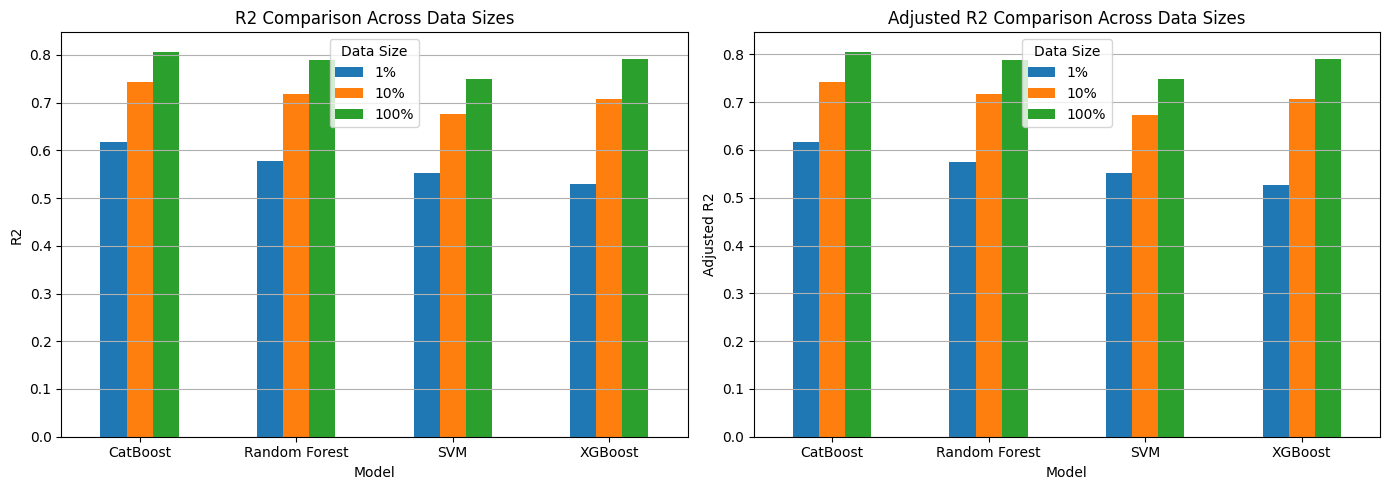

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

pivot_r2 = comparison_df.pivot(index="Model", columns="Data Size", values="R2")
pivot_r2.plot(kind="bar", ax=axes[0])
axes[0].set_title("R2 Comparison Across Data Sizes")
axes[0].set_ylabel("R2")
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis="y")

pivot_adj_r2 = comparison_df.pivot(index="Model", columns="Data Size", values="Adjusted R2")
pivot_adj_r2.plot(kind="bar", ax=axes[1])
axes[1].set_title("Adjusted R2 Comparison Across Data Sizes")
axes[1].set_ylabel("Adjusted R2")
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()


## **Choose the Best Model**

Selected using the same criterion as the rest of the notebook — lowest RMSE on the full test set — for consistency.

Select the Best Mode

In [ ]:
best_model = results.loc[results["RMSE"].idxmin()]

print("Best Model")

print(best_model)

Best Model
Model          CatBoost
MAE            0.257918
MSE            0.132367
RMSE           0.363823
R2             0.806815
Adjusted R2    0.805902
Name: 5, dtype: object


# **Hyperparameter Tuning (GridSearchCV) — Random Forest**

This project specifically tunes **Random Forest**, regardless of which model scored best overall above.

**Hyperparameters being tuned, explained simply:**
- **`n_estimators`** — how many individual trees the forest builds and averages. More trees usually means steadier predictions, at the cost of longer training time.
- **`max_depth`** — how many questions deep each tree is allowed to go before deciding. Too deep risks memorizing the training data (overfitting); too shallow risks missing real patterns (underfitting).
- **`min_samples_split`** — the smallest group size a tree is allowed to split further. Higher values keep the tree simpler.
- **`min_samples_leaf`** — the smallest number of listings allowed to end up in a single final branch. Prevents the tree from making decisions based on just 1-2 listings.
- **`max_features`** — how many columns each tree is allowed to consider at each split. Limiting this adds randomness between trees, which helps reduce overfitting.


In [ ]:
print("Overall best model (for reference):", best_model["Model"])
print("Model being tuned with GridSearchCV: Random Forest")


Overall best model (for reference): CatBoost
Model being tuned with GridSearchCV: Random Forest


In [ ]:
base_estimator = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}


In [ ]:
from sklearn.metrics import make_scorer

def adjusted_r2_scorer_func(y_true, y_pred, n_features):
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    return 1 - (1 - r2) * (n - 1) / (n - n_features - 1)

adj_r2_scorer = make_scorer(
    adjusted_r2_scorer_func,
    n_features=x_train_scaled.shape[1]
)


**Note on `GridSearchCV` vs `RandomizedSearchCV`:** we initially tried running a full `GridSearchCV` over the grid above. It ran for roughly **3 hours** without finishing, and partway through a power outage interrupted it entirely. Given the time cost, we switched to `RandomizedSearchCV`, which samples a fixed number of random combinations (`n_iter=30`) from the same grid instead of trying all of them — it finishes in a fraction of the time and, in practice, tends to land very close to the same result as a full grid search. The `GridSearchCV` code is kept below (commented out) for reference.


In [ ]:
"""
grid_search = GridSearchCV(
    estimator=base_estimator,
    param_grid=param_grid,
    scoring=adj_r2_scorer,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train_scaled, y_train)

print("Best Parameters found:", grid_search.best_params_)
print("Best CV Adjusted R2:", grid_search.best_score_)

tuned_model = grid_search.best_estimator_
"""

'\ngrid_search = GridSearchCV(\n    estimator=base_estimator,\n    param_grid=param_grid,\n    scoring=adj_r2_scorer,\n    cv=5,\n    n_jobs=-1,\n    verbose=1\n)\n\ngrid_search.fit(x_train_scaled, y_train)\n\nprint("Best Parameters found:", grid_search.best_params_)\nprint("Best CV Adjusted R2:", grid_search.best_score_)\n\ntuned_model = grid_search.best_estimator_\n'

In [ ]:
random_search = RandomizedSearchCV(
    estimator=base_estimator,
    param_distributions=param_grid,
    n_iter=30,
    scoring=adj_r2_scorer,
    cv=5,
    n_jobs=-1,
    random_state=42,
    verbose=1
)
random_search.fit(x_train_scaled, y_train)

print("Best Parameters found:", random_search.best_params_)
print("Best CV Adjusted R2:", random_search.best_score_)

tuned_model = random_search.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters found: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 20}
Best CV Adjusted R2: 0.7768518995113551


`tuned_model` is set to `random_search.best_estimator_` — the Random Forest already refit on the full training data using the best hyperparameter combination `RandomizedSearchCV` found. This is the exact object we evaluate below and save at the end of the notebook.

# **Model Evaluation (Before vs After Tuning)**

Compare the **same model** (Random Forest) before and after tuning, on both Train and Test data, using MAE, MSE, RMSE, R², and Adjusted R² — a bigger Train/Test gap signals overfitting, and improved Test metrics after tuning confirm the search was actually worth it.

In [ ]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    pred_train = model.predict(X_tr)
    pred_test  = model.predict(X_te)

    r2_train = r2_score(y_tr, pred_train)
    r2_test  = r2_score(y_te, pred_test)

    return {
        'Train MAE':  mean_absolute_error(y_tr, pred_train),
        'Test MAE':   mean_absolute_error(y_te, pred_test),
        'Train MSE':  mean_squared_error(y_tr, pred_train),
        'Test MSE':   mean_squared_error(y_te, pred_test),
        'Train RMSE': np.sqrt(mean_squared_error(y_tr, pred_train)),
        'Test RMSE':  np.sqrt(mean_squared_error(y_te, pred_test)),
        'Train R2':   r2_train,
        'Test R2':    r2_test,
        'Train Adjusted R2': adjusted_r2_score(r2_train, X_tr.shape[0], X_tr.shape[1]),
        'Test Adjusted R2':  adjusted_r2_score(r2_test, X_te.shape[0], X_te.shape[1]),
    }


In [ ]:
before_model = forest_model

In [ ]:
before_metrics = evaluate(before_model, x_train_scaled, y_train, x_test_scaled, y_test)
after_metrics  = evaluate(tuned_model,  x_train_scaled, y_train, x_test_scaled, y_test)

In [ ]:
comparison = pd.DataFrame({
    'Before GridSearchCV': before_metrics,
    'After GridSearchCV':  after_metrics
})

comparison

,Before GridSearchCV,After GridSearchCV
Train MAE,0.098119,0.111653
Test MAE,0.264244,0.264748
Train MSE,0.020818,0.024674
Test MSE,0.143953,0.144165
Train RMSE,0.144286,0.157081
Test RMSE,0.379411,0.379691
Train R2,0.970101,0.964563
Test R2,0.789907,0.789597
Train Adjusted R2,0.970066,0.964521
Test Adjusted R2,0.788914,0.788603


# **Save Model**

We save everything needed to reuse this project without re-running the whole notebook:

- **`model_random_forest_tuned.pkl`** — the actual model we'd deploy: `tuned_model`, i.e. `random_search.best_estimator_`, the Random Forest fit with the best hyperparameters `RandomizedSearchCV` found.
- **The other five baseline models** (`linear_model`, `tree_model`, `forest_model`, `xgb_model`, `svm_model`, `catboost_model`) — saved too, so the full model comparison (Task 5) can be reproduced or extended later without retraining everything from scratch.
- **Preprocessing objects** (`scaler`, the frequency-encoding maps for `neighbourhood_cleansed`/`property_type`, and the final `feature_columns` list) — required to transform any *new*, raw input the exact same way the training data was transformed. Without saving these, a saved model alone would be useless on new data, since it expects scaled/encoded features in a specific column order.
- **`baseline_results.csv`** and **`tuning_comparison.csv`** — the evaluation tables themselves, so a deployed app could display the model comparison and the tuning before/after results without having to recompute them.

All of this goes into a single `deployment_assets/` folder, mirroring how a real project separates "things needed for inference" from "the notebook used to build them".


In [ ]:
import joblib
import os

os.makedirs('deployment_assets', exist_ok=True)

# --- Final production model (tuned Random Forest) ---
joblib.dump(tuned_model, 'deployment_assets/model_random_forest_tuned.pkl')

# --- All baseline models (for comparison / model-selection in the app) ---
joblib.dump(linear_model,   'deployment_assets/model_linear_regression.pkl')
joblib.dump(tree_model,     'deployment_assets/model_decision_tree.pkl')
joblib.dump(forest_model,   'deployment_assets/model_random_forest.pkl')
joblib.dump(xgb_model,      'deployment_assets/model_xgboost.pkl')
joblib.dump(svm_model,      'deployment_assets/model_svm.pkl')
joblib.dump(catboost_model, 'deployment_assets/model_catboost.pkl')

# --- Preprocessing objects needed to transform raw user input the same way as training ---
joblib.dump(scaler, 'deployment_assets/scaler.pkl')
joblib.dump(freq_neighbourhood.to_dict(), 'deployment_assets/freq_neighbourhood.pkl')
joblib.dump(freq_property.to_dict(), 'deployment_assets/freq_property.pkl')
joblib.dump(x.columns.tolist(), 'deployment_assets/feature_columns.pkl')

# --- Evaluation results (so the deployed app can show model comparison without retraining) ---
results.to_csv('deployment_assets/baseline_results.csv', index=False)
comparison.to_csv('deployment_assets/tuning_comparison.csv')

print("All models and preprocessing objects saved to 'deployment_assets/'")
print(os.listdir('deployment_assets'))


All models and preprocessing objects saved to 'deployment_assets/'
['freq_neighbourhood.pkl', 'model_svm.pkl', 'model_xgboost.pkl', 'freq_property.pkl', 'model_random_forest_tuned.pkl', 'model_decision_tree.pkl', 'feature_columns.pkl', 'model_random_forest.pkl', 'model_catboost.pkl', 'scaler.pkl', 'tuning_comparison.csv', 'model_linear_regression.pkl', 'baseline_results.csv']
